In [34]:
%matplotlib widget
import importlib
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import pandas as pd
import io
import matplotlib



os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\COMSOL\Acoustic')
import Treat_acoustic_func as Treat_acoustic_func
importlib.reload(Treat_acoustic_func)
from Treat_acoustic_func import *


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\COMSOL\Acoustic')
import Treat_acoustic_plotting as Treat_acoustic_plotting
importlib.reload(Treat_acoustic_plotting)
from Treat_acoustic_plotting import *




fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18

In [35]:
dir_root = r'H:\commun\Utilisateur FNO\Nathan\COMSOL\AuND\Acoustic\Sapphire\PML size study - AR 6'


Shape_choice = 'cylinder'
Sizes = ['200nm', '400nm', '600nm']

Spectra_data = {}
Colors = {}
compt=0

cm = plt.get_cmap('gist_rainbow')
Colors_list = [matplotlib.colors.to_hex(cm(1.*i/np.size(Sizes))) for i in range(np.size(Sizes))]


for size in Sizes :
    Colors[size] = Colors_list[compt]
    compt +=1
    dir_spectra= '\\'.join((dir_root, Shape_choice, 'PML - scaling factor 5'))
    Fname_list = ['size_sweep_AR_4_8 - PML size ' + size]
    n_parameters=2
    Spectra_data[size]= get_raw_size_sweep_data_Nathan(dir_spectra, Fname_list, verbose=True)

C:\Users\nberr\ENS_Lyon\Thèse\Code\COMSOL\Acoustic\Treat_acoustic_func.py:97: ParserWarning:

Both a converter and dtype were specified for column % D (m) - only the converter will be used.

C:\Users\nberr\ENS_Lyon\Thèse\Code\COMSOL\Acoustic\Treat_acoustic_func.py:98: FutureWarning:

DataFrame.applymap has been deprecated. Use DataFrame.map instead.

C:\Users\nberr\ENS_Lyon\Thèse\Code\COMSOL\Acoustic\Treat_acoustic_func.py:97: ParserWarning:

Both a converter and dtype were specified for column % D (m) - only the converter will be used.

C:\Users\nberr\ENS_Lyon\Thèse\Code\COMSOL\Acoustic\Treat_acoustic_func.py:98: FutureWarning:

DataFrame.applymap has been deprecated. Use DataFrame.map instead.



Total size of raw data : 2050
----------- Find spectra size -----------
idx start : 0
value start : (1.0611352081309838e-06+1.3977861885366676e-06j)
end index : 49
value end : (26.056669122899464+0.19089660909591025j)
----------- Find spectra size -----------
idx start : 50
value start : (5.410620792037411e-07-5.568808982008721e-08j)
end index : 99
value end : (25.88489115665148+0.18649878786705332j)
----------- Find spectra size -----------
idx start : 100
value start : (2.1402467425316544e-07+1.6031739425947216e-06j)
end index : 149
value end : (25.718885537494273+0.18351952979073335j)
----------- Find spectra size -----------
idx start : 150
value start : (1.0620834853203253e-06+1.0386536699364832e-07j)
end index : 199
value end : (25.55781373551977+0.18166462374746023j)
----------- Find spectra size -----------
idx start : 200
value start : (5.035254743099891e-07-1.5509912134851538e-06j)
end index : 249
value end : (25.40138930664636+0.18081978672643167j)
----------- Find spectra s

C:\Users\nberr\ENS_Lyon\Thèse\Code\COMSOL\Acoustic\Treat_acoustic_func.py:97: ParserWarning:

Both a converter and dtype were specified for column % D (m) - only the converter will be used.

C:\Users\nberr\ENS_Lyon\Thèse\Code\COMSOL\Acoustic\Treat_acoustic_func.py:98: FutureWarning:

DataFrame.applymap has been deprecated. Use DataFrame.map instead.



In [36]:
#plot_all_raw_spectra_interactive(Spectra_cylinder)

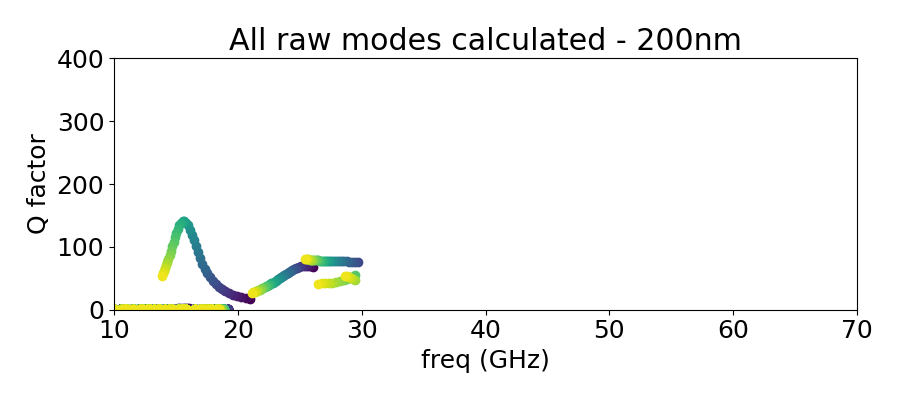

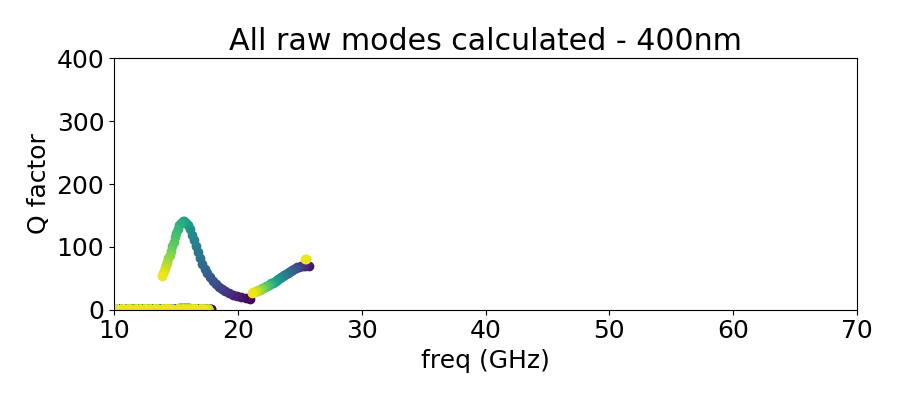

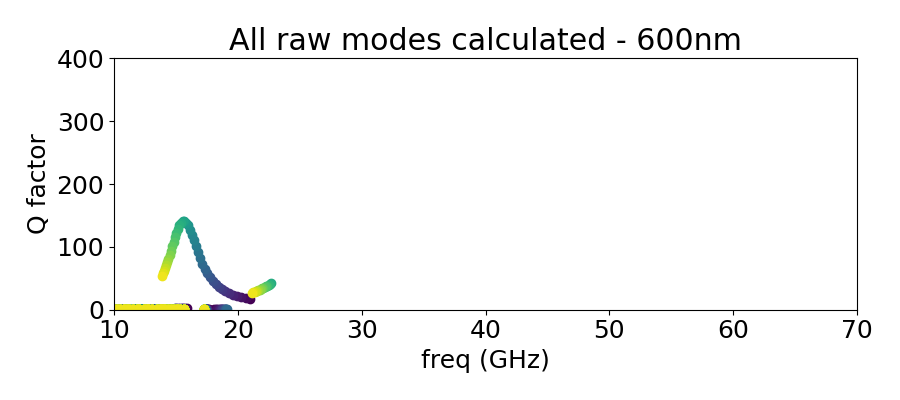

In [37]:
bottom = 0
top=400
xlim = (10, 70)

for key in Spectra_data :
    spectra = Spectra_data[key]

    fig, ax = plt.subplots(figsize = (9,4))

    plot_all_raw_spectra(spectra, ax, plotted_key = 'Q')

    ax.set_xlabel('freq (GHz)')
    ax.set_ylabel('Q factor')
    ax.set_ylim(bottom=bottom )
    ax.set_ylim( top=top)
    ax.set_xlim(xlim)
    ax.set_title('All raw modes calculated - ' + key)
    #plt.legend(fontsize=10)
    plt.tight_layout()





In [38]:
for key in Spectra_data :
    spectra = Spectra_data[key]
    get_modes_with_Q_selection(spectra, Q_th=3)

## def freq limit functions to extract Q factor

In [39]:
## For cylinder

def f1_low(ar) :
    return(38/(ar**0.5))

def f1_high(ar) :
    return(60/(ar**0.48))

## For round corner

def f2_low(ar) :
    return(35/(ar**0.5))

def f2_high(ar) :
    return(60/(ar**0.48))


## For round
def f3_low(ar) :
    return(38/(ar**0.5))

def f3_high(ar) :
    return(60/(ar**0.5))


Boundary_func = {}
Boundary_func['200nm'] = (f1_low, f1_high)
Boundary_func['400nm'] = (f1_low, f1_high)
Boundary_func['600nm'] = (f1_low, f1_high)

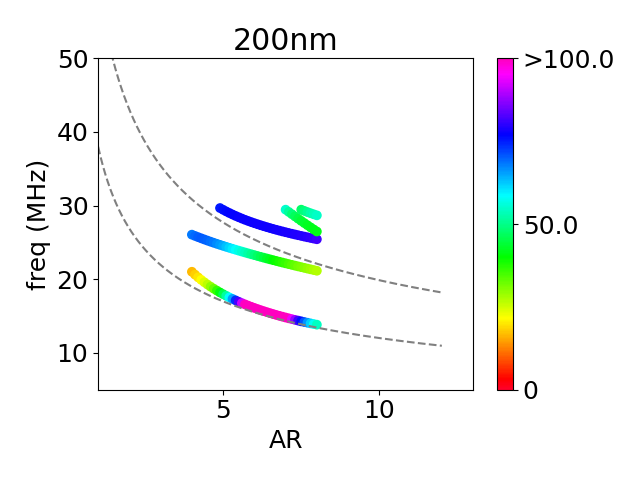

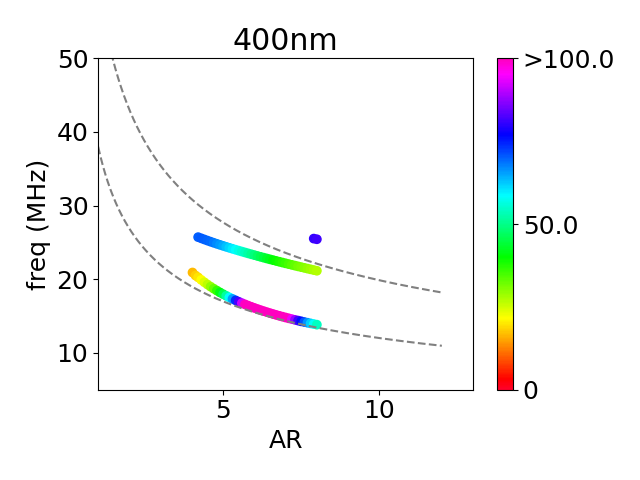

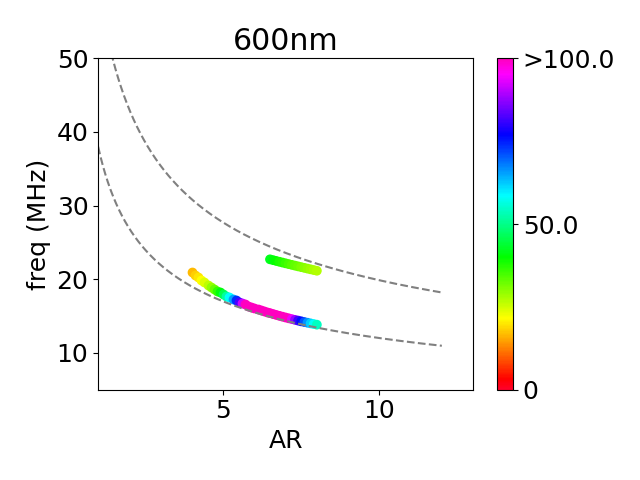

In [40]:
Q_max = 100
xlim = (1, 13)
ylim = (5, 50)
AR_array = np.linspace(1, 12, 1000)


for key in Spectra_data :
    spectra = Spectra_data[key]
   


    fig, ax = plt.subplots()
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    plt.xlabel('AR')
    plt.ylabel('freq (MHz)')
    plt.title(key)
    


    plot_all_acoustic_modes(spectra, ax, Q_max = Q_max, n_modes = 5)
    plt.tight_layout()

    ax.plot(AR_array, Boundary_func[key][0](AR_array), linestyle='--', color='grey')
    ax.plot(AR_array, Boundary_func[key][1](AR_array), linestyle='--', color='grey')



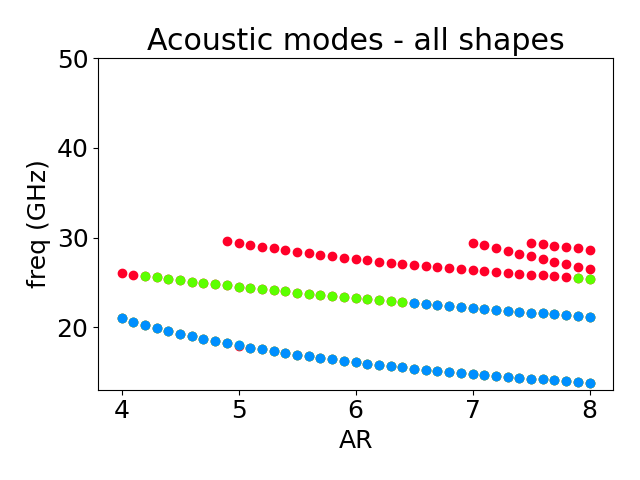

In [41]:
fig, ax = plt.subplots()

for key in Spectra_data :
    spectra = Spectra_data[key]
    


    for kkey in spectra :
        single_ND_modes = spectra[kkey]
        #print(np.sum(spectra['projection']))
        #print(spectra['eigen_freq'][np.argmax(spectra['projection'])])
        ax.scatter(single_ND_modes['AR']*np.ones(np.size(single_ND_modes['modes']['f'])), single_ND_modes['modes']['f'], color=Colors[key])

plt.title('Acoustic modes - all shapes')
plt.ylim(top=50)
plt.xlabel('AR')
plt.ylabel('freq (GHz)')
plt.tight_layout()

dir_to_save = dir_root  + r'\Figures'
if not(os.path.exists(dir_to_save)) :
    os.mkdir(dir_to_save)
os.chdir(dir_to_save)
plt.savefig('freq(AR) - all shapes.pdf')
plt.savefig('freq(AR) - all shapes.png')



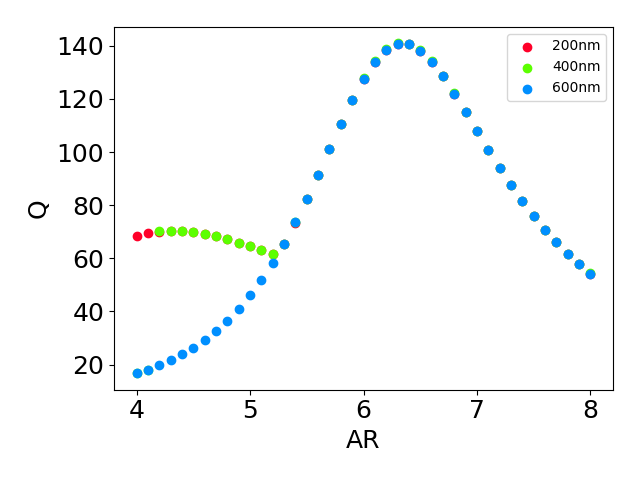

In [42]:
AR_min = 1
AR_max = 12

fig, ax = plt.subplots()



for key in Spectra_data :
    spectra = Spectra_data[key]
    AR, Q = get_max_Q(spectra, freq_low_func=Boundary_func[key][0], freq_high_func=Boundary_func[key][1],AR_min=AR_min, AR_max=AR_max)
    ax.scatter(AR, Q, color=Colors[key], label = key)


plt.xlabel('AR')
plt.ylabel('Q')
plt.legend(fontsize=10)
plt.tight_layout()




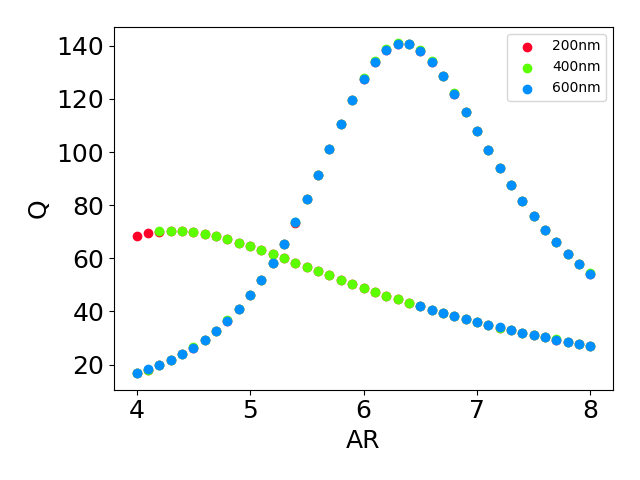

In [43]:


AR_all_shapes = {}
Q_all_shapes = {}
Freq_all_shapes = {}

fig, ax = plt.subplots()

for key in Spectra_data :
    spectra = Spectra_data[key]
    AR_all_shapes[key],  Freq_all_shapes[key], Q_all_shapes[key] = get_Q_specific_bands(spectra, freq_low_func=Boundary_func[key][0], freq_high_func=Boundary_func[key][1], AR_min=AR_min, AR_max=AR_max)
    ax.scatter(AR_all_shapes[key],  Q_all_shapes[key], color=Colors[key], label = key)

plt.xlabel('AR')
plt.ylabel('Q')
plt.legend(fontsize=10)
plt.tight_layout()


dir_to_save = dir_root  + r'\Figures'
if not(os.path.exists(dir_to_save)) :
    os.mkdir(dir_to_save)
os.chdir(dir_to_save)
plt.savefig('Q(AR) - all shapes.pdf')
plt.savefig('Q(AR) - all shapes.png')

## Save data

In [44]:
if 0 :
    for key in Spectra_data :
        spectra = Spectra_data[key]


        dir_to_save = dir_root + r'\\' + key + r'\Treated data'
        save_Q_with_AR_to_csv(dir_to_save, 'Selected acoustic modes', Q_all_shapes[key], AR_all_shapes[key], Freq_all_shapes[key])
        save_freq_with_AR_to_csv(dir_to_save, 'Q and freq', spectra)
